![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | EDA and Baseline

*Project 2 — Machine Learning: From Data to Predictions*

**Team: Zoé Doucet**
**Dataset: Covertype**

---

Steps 1 to 4 of the workflow: frame the problem, look at the data, split once, and score the baseline every model will have to beat.

> **Done when:** your framing is written down, you know what is broken in the data and which columns must go, the split is fixed, and you have a baseline score from cross-validation.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

In [ ]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay, make_scorer)
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. The problem

Dataset: Covertype (https://archive.ics.uci.edu/dataset/31/covertype)

 Created by Jock Blackard

 Classification of pixels into 7 forest cover types based on attributes such as elevation, aspect, slope, hillshade, soil-type, and more.

The Covertype dataset is used in this machine learning project to predict the type of forest cover expected in a specific plot of land. The dataset contains cartographic variables for 30 × 30 metre land cells in four wilderness areas of the Roosevelt National Forest in northern Colorado. The forest cover types were determined using data from the US Forest Service, while the independent variables were derived from data originally obtained from the US Geological Survey and the US Forest Service. These variables describe the geographical characteristics of the land, without using remotely sensed data.

The goal of the project is to build a machine learning classification model that can **predict the forest cover type** based on these cartographic variables. The model could help anticipate which type of forest is likely to occur in a given area. The **target** variable is the forest **covertype**, while the remaining variables serve as input features. To evaluate its performance, accuracy and recall will be used. **Accuracy** measures the overall proportion of correct predictions, while **recall** measures how effectively the model identifies each forest covertype. Particular attention will be paid to misclassified observations to identify where the model struggles and how its classification performance could be improved.

---
## 2. Loading the data

The goal of this project is to build a machine learning classification model that predicts the forest cover type of a given plot of land. As part of the project, different data preparation techniques will be explored, such as feature selection and the handling of categorical variables, to understand how these steps can influence model performance.

However, the Covertype dataset is already partially prepared for machine learning: the target variable (forest covertype) is separated from the features, and categorical variables such as soil types and wilderness areas are already represented as binary columns using one-hot encoding. To demonstrate the data preparation process and explore alternative ways of representing categorical variables, the target and feature datasets will first be recombined. The binary columns representing soil types and wilderness areas will then be transformed back into two categorical columns, one for soil type and one for wilderness area. 

In [88]:
#pip install ucimlrepo 
# importing the dataset from ucimlrepo
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
covertype = fetch_ucirepo(id=31) 
# data (as pandas dataframes) 
X_c = covertype.data.features 
y_c = covertype.data.targets 

# concatinating the features and targets into one dataset
covertype_concat = pd.concat([X_c, y_c], axis=1)

# creating a dictionnary with the binary columns that will be convertet to categorical columns
column_groups = {"Soil_Type":[f"Soil_Type{i}" for i in range (1, 41)], # the range represetns the different classes 
                 "Wilderness_Area":[f"Wilderness_Area{i}"for i in range(1,5)]}

# converting the binary columns into two categorical columns
covertype_raw = convert_binary_columns(covertype_concat, column_groups)


In [27]:
# saving the raw data
covertype_raw.to_csv("../data/raw/covertype_raw.csv", index=False)

If the data has already been converted start here

In [89]:
# load the raw data
covertype_raw = pd.read_csv("../data/raw/covertype_raw.csv")

---
## 3. First look

Shape, column types, a handful of rows. What is one row of this data, and what is the target column?

In [90]:
covertype_raw.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,Cover_Type,Soil_Type,Wilderness_Area
0,2596,51,3,258,0,510,221,232,148,6279,5,29,1
1,2590,56,2,212,-6,390,220,235,151,6225,5,29,1
2,2804,139,9,268,65,3180,234,238,135,6121,2,12,1
3,2785,155,18,242,118,3090,238,238,122,6211,2,30,1
4,2595,45,2,153,-1,391,220,234,150,6172,5,29,1


In [ ]:
covertype_raw.shape # 581012, 13

(581012, 13)

In [ ]:
covertype_raw.columns.tolist() # list of all the column names

['Elevation',
 'Aspect',
 'Slope',
 'Horizontal_Distance_To_Hydrology',
 'Vertical_Distance_To_Hydrology',
 'Horizontal_Distance_To_Roadways',
 'Hillshade_9am',
 'Hillshade_Noon',
 'Hillshade_3pm',
 'Horizontal_Distance_To_Fire_Points',
 'Cover_Type',
 'Soil_Type',
 'Wilderness_Area']

In [ ]:
covertype_raw.columns.is_unique # all the column names are unique

True

In [ ]:
covertype_raw.dtypes # all columns appear to have integer data type

Elevation                             int64
Aspect                                int64
Slope                                 int64
Horizontal_Distance_To_Hydrology      int64
Vertical_Distance_To_Hydrology        int64
Horizontal_Distance_To_Roadways       int64
Hillshade_9am                         int64
Hillshade_Noon                        int64
Hillshade_3pm                         int64
Horizontal_Distance_To_Fire_Points    int64
Cover_Type                            int64
Soil_Type                             int64
Wilderness_Area                       int64
dtype: object

The Covertype dataset contains 581,012 rows and 13 columns. Each row represents a 30 × 30 metre land cell and includes information about its geographical characteristics, such as elevation, aspect, slope, horizontal and vertical distance to hydrology, horizontal distance to roadways and fire points, and hillshade measurements at 9 a.m., noon and 3 p.m. The dataset also contains the soil type, wilderness area and forest cover type of each land cell.

All columns have unique names and use the integer data type. However, the **column names will be standardised** using snake_case for better readability and consistency. Although `Soil_Type` and `Wilderness_Area` contain integers, these values represent categorical classes rather than numerical measurements. These columns will be separated into **binary columns** for each class using **One Hot Encoding** when building the processing pipelines.

The **target** variable is `Cover_Type`, which identifies the forest cover class of each land cell using a numerical label. The objective of the machine learning model will be to predict this class based on the remaining features.

---
## 4. Data quality

Missing values (including ones in disguise, such as `"unknown"`, blanks or `999`), duplicates, numbers stored as text, dates stored as strings. Write down what you find and what you will do about it.

In [ ]:
# looking for null values
covertype_raw.isna().sum() # the dataset does not contain null values

Elevation                             0
Aspect                                0
Slope                                 0
Horizontal_Distance_To_Hydrology      0
Vertical_Distance_To_Hydrology        0
Horizontal_Distance_To_Roadways       0
Hillshade_9am                         0
Hillshade_Noon                        0
Hillshade_3pm                         0
Horizontal_Distance_To_Fire_Points    0
Cover_Type                            0
Soil_Type                             0
Wilderness_Area                       0
dtype: int64

In [ ]:
# looking for duplicates
covertype_raw.duplicated().sum() # the dataset does not contain duplicates

np.int64(0)

In [ ]:
# checking if categorical columns have the right number of classes
print(f"Soil type:{covertype_raw["Soil_Type"].nunique()}") # expected number of classes: 40
print(f"Wilderness area:{covertype_raw["Wilderness_Area"].nunique()}") # expected number of classes: 4

Soil type:40
Wilderness area:4


In [ ]:
# does the data make sense?
covertype_raw.describe().T[["mean", "min", "max", "std"]] # taking a loook at mean, maximal, minimal values as well as standard deviation

,mean,min,max,std
elevation,2959.365301,1859.0,3858.0,279.984734
aspect,155.656807,0.0,360.0,111.913721
slope,14.103704,0.0,66.0,7.488242
horizontal_distance_to_hydrology,269.428217,0.0,1397.0,212.549356
vertical_distance_to_hydrology,46.418855,-173.0,601.0,58.295232
horizontal_distance_to_roadways,2350.146611,0.0,7117.0,1559.254870
hillshade_9am,212.146049,0.0,254.0,26.769889
hillshade_noon,223.318716,0.0,254.0,19.768697
hillshade_3pm,142.528263,0.0,254.0,38.274529
horizontal_distance_to_fire_points,1980.291226,0.0,7173.0,1324.195210


The dataset does not contain null values or duplicates. All categorical columns have the expected number of classes.
Taking a closer look at the data, we can see some negative values as well as zeros. However for each column these values are realistic.

---
## 5. Numeric columns
Identifiers, and **anything that would not be known at the moment you make a prediction**. List them with the reason. A column that looks too good to be true usually is.

- Taking a closer look at all numeric columns ( not target or categorical columns)

In [ ]:
# creating a list of all numeric features
numeric_features_raw = ["Elevation",
                        "Aspect",
                        "Slope",
                        "Horizontal_Distance_To_Hydrology",
                        "Vertical_Distance_To_Hydrology",
                        "Horizontal_Distance_To_Roadways",
                        "Hillshade_9am",
                        "Hillshade_Noon",
                        "Hillshade_3pm",
                        "Horizontal_Distance_To_Fire_Points"]

In [91]:
# taking a closer look at the features mean. maximal and minimal values as well as the standard deviation
covertype_raw[numeric_features_raw].describe().T[["mean", "min", "max", "std"]]

,mean,min,max,std
Elevation,2959.365301,1859.0,3858.0,279.984734
Aspect,155.656807,0.0,360.0,111.913721
Slope,14.103704,0.0,66.0,7.488242
Horizontal_Distance_To_Hydrology,269.428217,0.0,1397.0,212.549356
Vertical_Distance_To_Hydrology,46.418855,-173.0,601.0,58.295232
Horizontal_Distance_To_Roadways,2350.146611,0.0,7117.0,1559.254870
Hillshade_9am,212.146049,0.0,254.0,26.769889
Hillshade_Noon,223.318716,0.0,254.0,19.768697
Hillshade_3pm,142.528263,0.0,254.0,38.274529
Horizontal_Distance_To_Fire_Points,1980.291226,0.0,7173.0,1324.195210


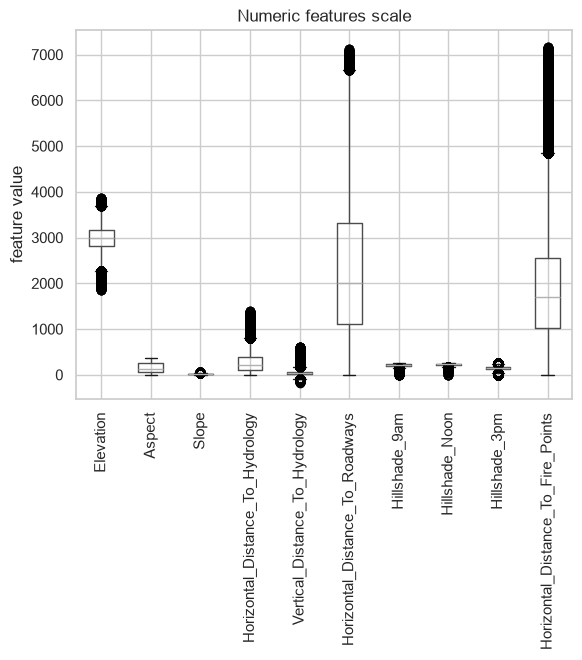

In [92]:
bx = covertype_raw[numeric_features_raw].boxplot() # creating a boxplot for al numeric features
bx.set_title("Numeric features scale")
bx.set_ylabel("feature value")
bx.tick_params(axis="x", labelrotation=90)

The boxplots, along with the mean, minimum, maximum and standard deviation of the numerical features, show the differences in their scales. For example, the maximum value of `Slope` is much lower than the minimum value of `Elevation`. These differences suggest that scaling may be beneficial for scale-sensitive machine learning algorithms.

----
## 5. Processing

In [95]:
# column names will be standardised using snake_case
covertype_clean = column_names_std(covertype_raw)

In [60]:
# saving cleaned dataset
covertype_clean.to_csv("../data/covertype_clean.csv", index=False)

---
## 6. The target

Its distribution. For classification, the share of each class: this is what makes accuracy honest or misleading. For regression, is it skewed?

In [7]:
covertype_clean = pd.read_csv("../data/covertype_clean.csv")

In [8]:
# exact number of observations in each class
covertype_clean["cover_type"].value_counts()

cover_type
2    283301
1    211840
3     35754
7     20510
6     17367
5      9493
4      2747
Name: count, dtype: int64

In [9]:
# share of each class
round(covertype_clean["cover_type"].value_counts(normalize=True)*100,2)

cover_type
2    48.76
1    36.46
3     6.15
7     3.53
6     2.99
5     1.63
4     0.47
Name: proportion, dtype: float64

Text(0, 0.5, 'Number of Observations')

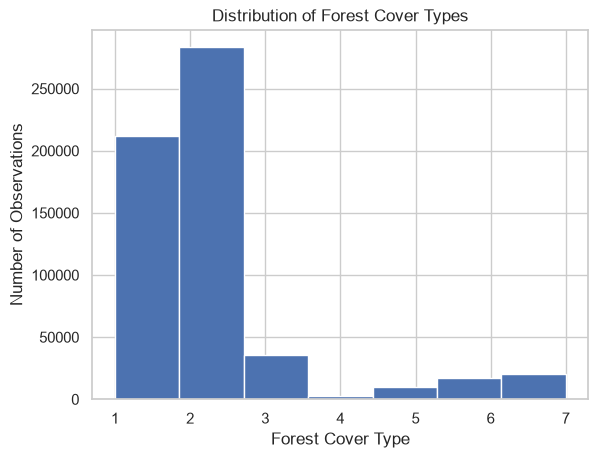

In [10]:
ax = covertype_clean["cover_type"].hist(bins=7) # visaulizing the share of each class for cover type
ax.set_title("Distribution of Forest Cover Types")
ax.set_xlabel("Forest Cover Type")
ax.set_ylabel("Number of Observations")

The target variable contains seven classes, as expected, but the class distribution is highly **imbalanced**. **Class 2** accounts for **48.76 %** of all observations, whereas **Class 4** represents only **0.47 %**. Therefore, a stratified train-test split should be used to preserve the class proportions in both sets.

---
## 7. Features against the target

Which features move with the target, and how? Numeric against target, categories against target. Write the takeaway under each chart.

In [96]:
numeric_features = ["elevation",
                        "aspect",
                        "slope",
                        "horizontal_distance_to_hydrology",
                        "vertical_distance_to_hydrology",
                        "horizontal_distance_to_roadways",
                        "hillshade_9am",
                        "hillshade_noon",
                        "hillshade_3pm",
                        "horizontal_distance_to_fire_points"]

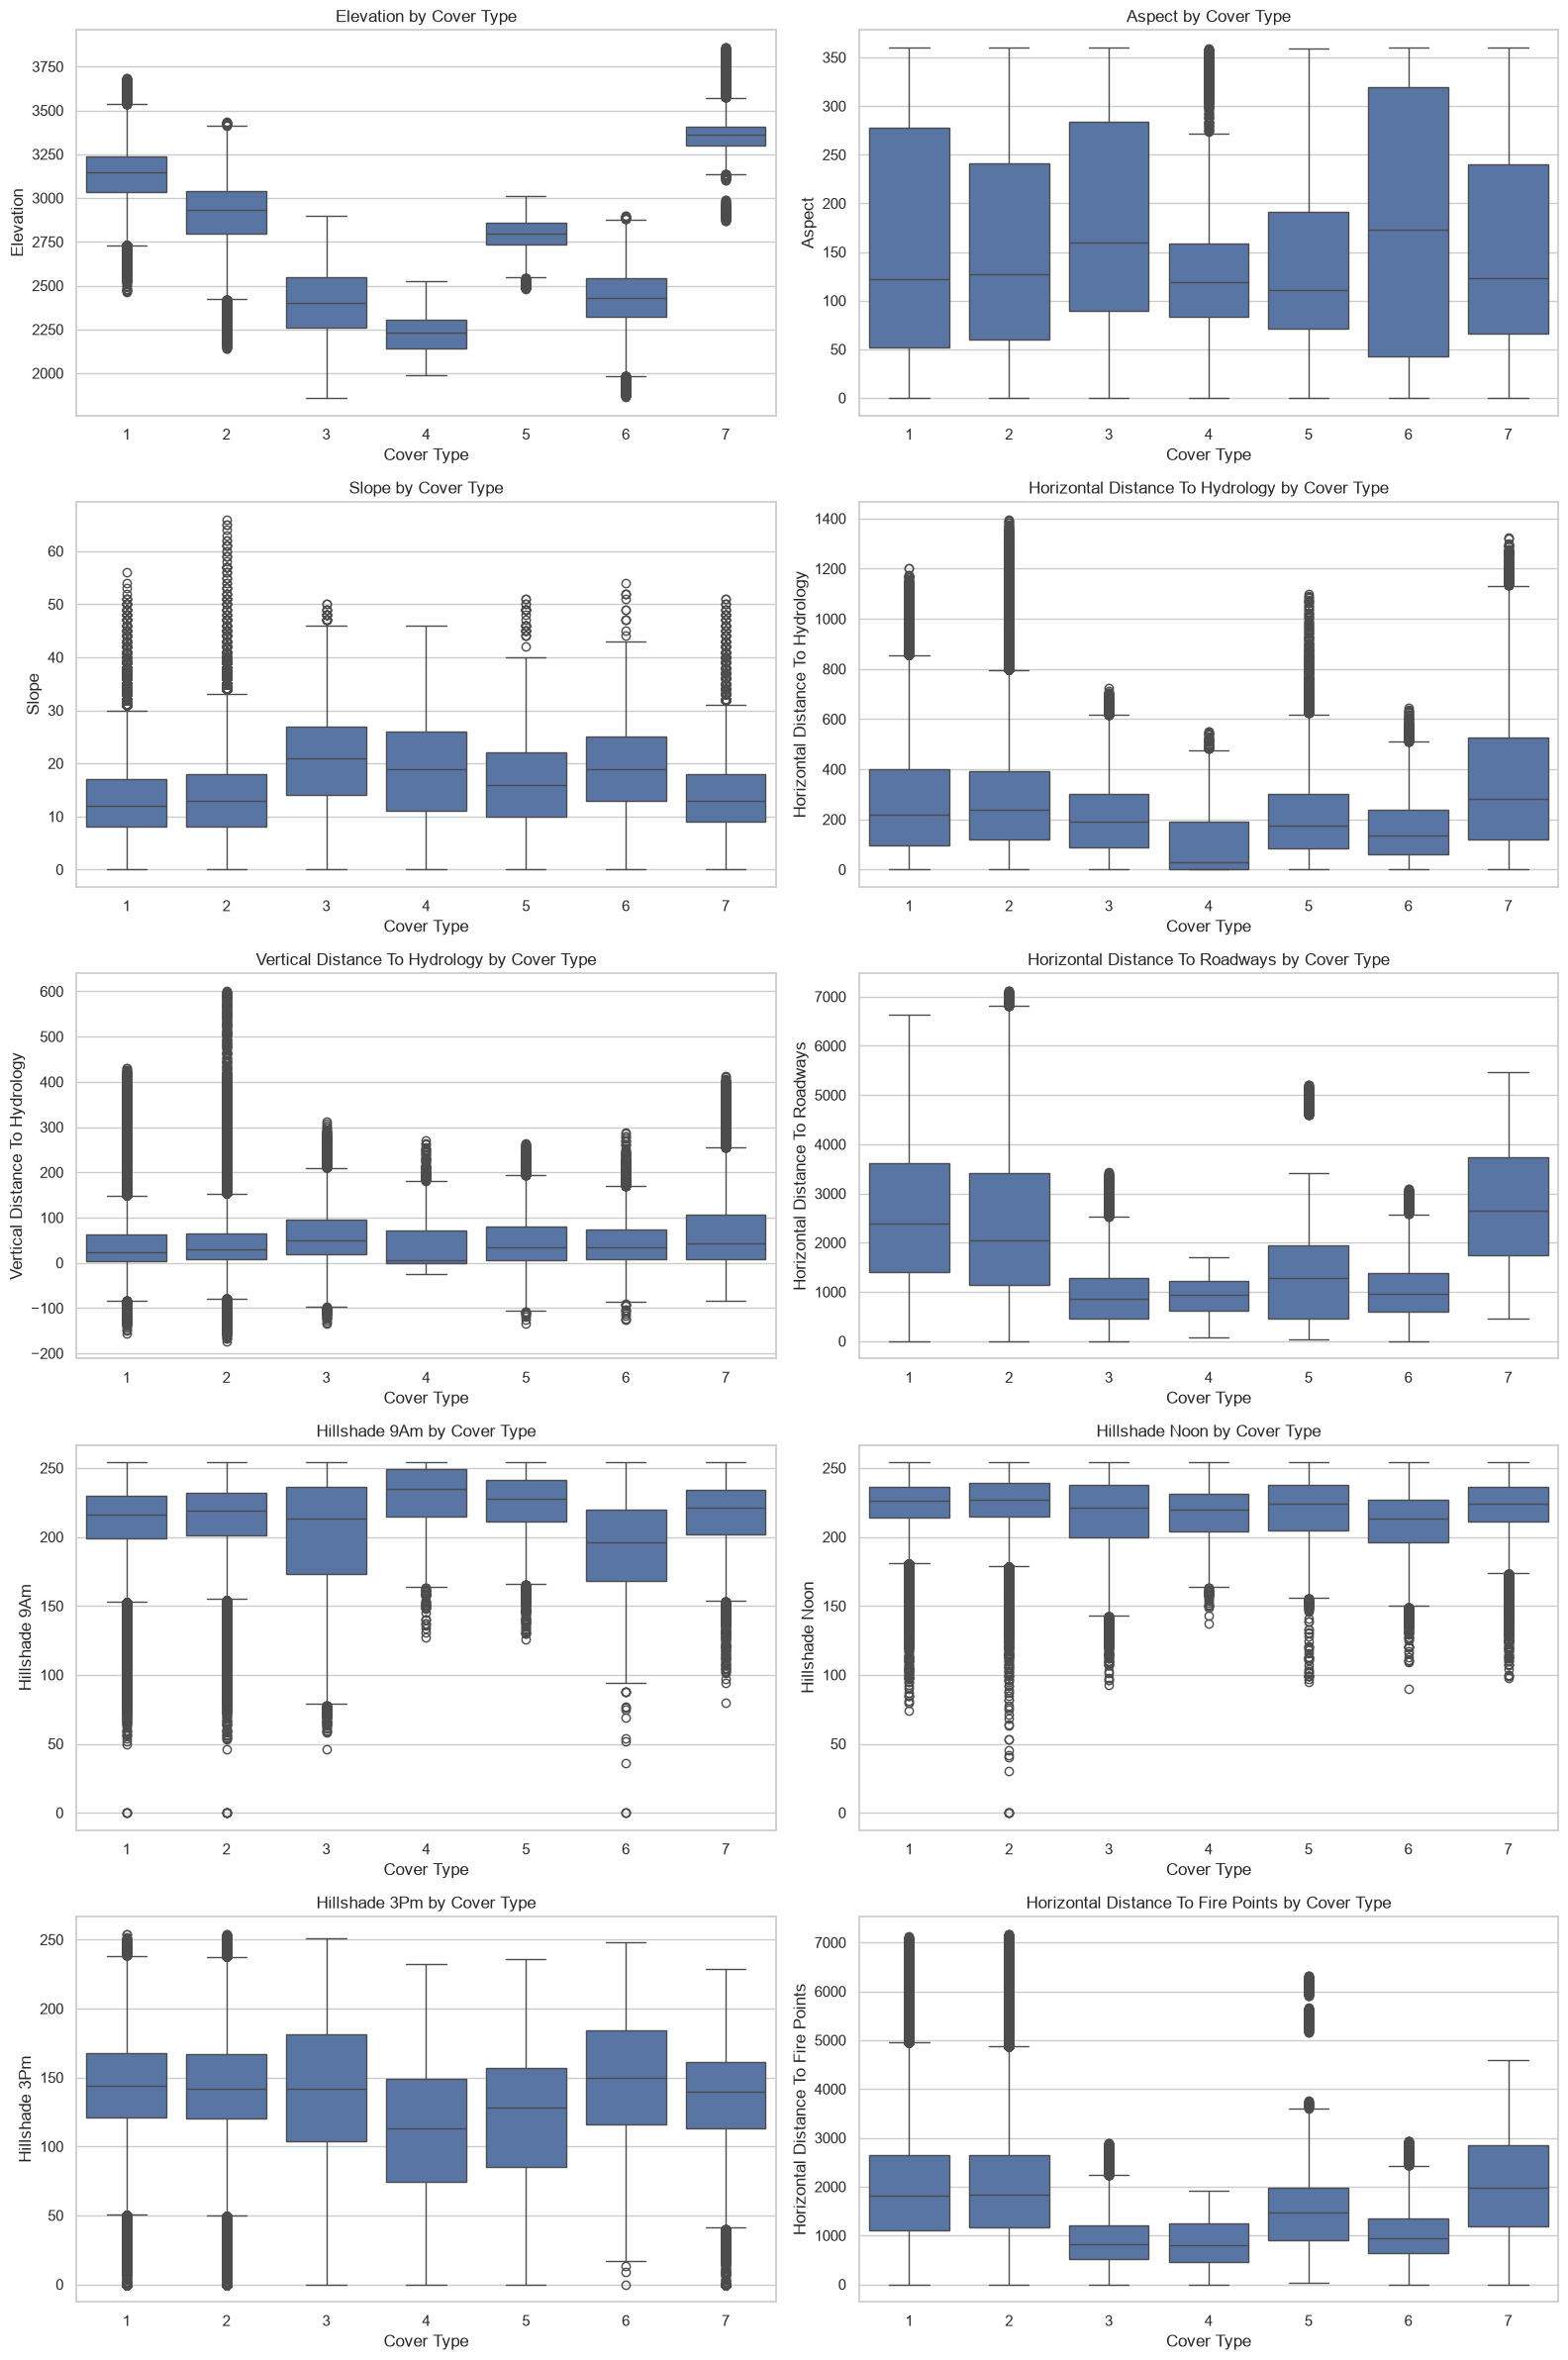

In [ ]:
fig, axes = plt.subplots(5, 2, figsize=(16, 24))
for feature, ax in zip(numeric_features, axes.flatten()):
    sns.boxplot(
        data=covertype_clean,
        x="cover_type",
        y=feature,
        ax=ax)
    ax.set_title(f"{feature.replace('_', ' ').title()} by Cover Type")
    ax.set_xlabel("Cover Type")
    ax.set_ylabel(feature.replace("_", " ").title())

plt.tight_layout()
plt.show()

Elevation appears to have a strong relationship with forest cover type. For the other numerical features, no clear trends are visible. However, aspect may influence the occurrence of cover type 4, while horizontal distance to roadways may also be associated with the target variable.

In [99]:
categorical_features = ["soil_type", "wilderness_area"]

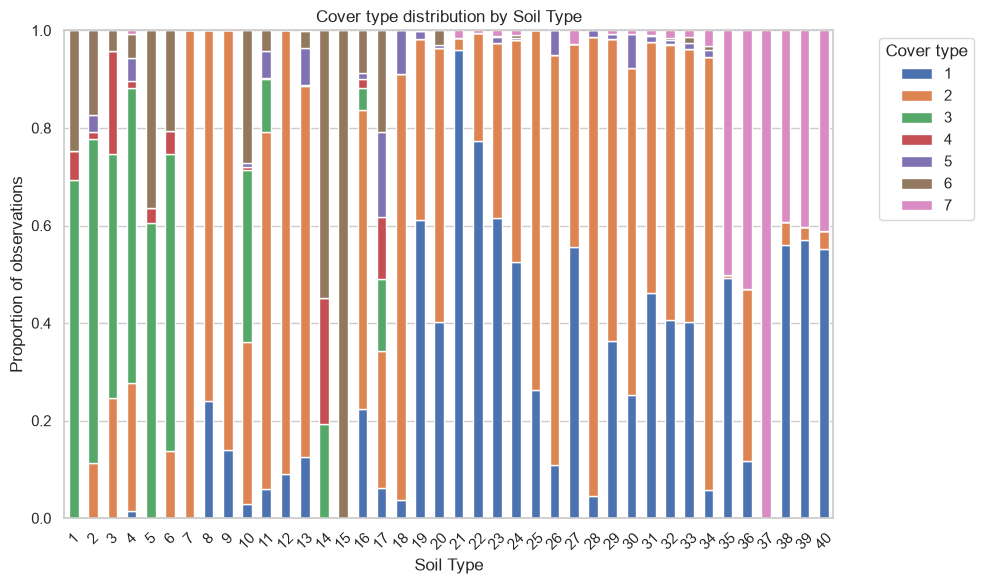

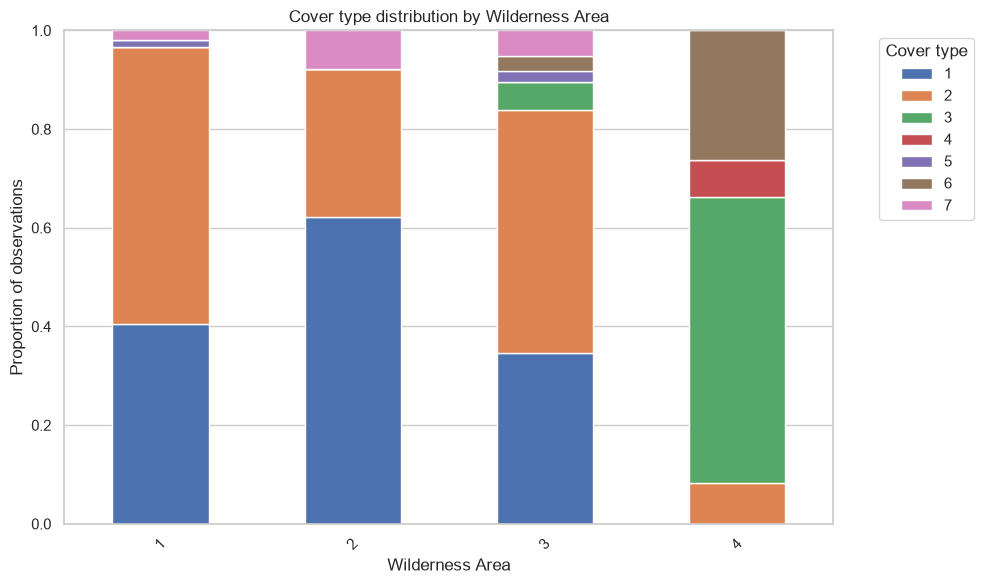

In [119]:
for feature in categorical_features:
    pd.crosstab(covertype_clean[feature], covertype_clean["cover_type"], normalize="index").plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6),
        rot=45)

    plt.title(f"Cover type distribution by {feature.replace('_', ' ').title()}")
    plt.xlabel(feature.replace("_", " ").title())
    plt.ylabel("Proportion of observations")
    plt.legend(title="Cover type", bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.show()

The stacked bar charts clearly show a relationship between soil type, wilderness area and forest cover type. For example, soil type 37 is associated exclusively with forest cover type 7, while forest cover type 4 occurs only in wilderness area 4. These observations suggest that both soil type and wilderness area may be important predictors for the classification model.

---
## 8. Split once

A fixed `random_state`, stratified for classification. From here on, everything happens on the training set; the test set waits until notebook 03.

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
# splitting the data
X = covertype_clean.drop(columns= ["cover_type"]) # features
y = covertype_clean["cover_type"] # target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify= y, random_state=42)
print(len(X_train), "training rows,", len(X_test), "test rows")

435759 training rows, 145253 test rows


The data has succesfully been split in 435759 training rows and 145253 test rows.

In [13]:
# checking if stratify worked well and the proportions of each class of cover type are similar
proportions = pd.DataFrame({
    "Original": y.value_counts(normalize=True).sort_index(),
    "Training": y_train.value_counts(normalize=True).sort_index(),
    "Test": y_test.value_counts(normalize=True).sort_index()}).round(4)

print(proportions)

# testing if orginal and training proportions match
print("\nOriginal and training proportions match:",
      np.allclose(proportions["Original"], proportions["Training"])) 
# testing if orginal and test proportions match
print("Original and test proportions match:",
      np.allclose(proportions["Original"], proportions["Test"]))

            Original  Training    Test
cover_type                            
1             0.3646    0.3646  0.3646
2             0.4876    0.4876  0.4876
3             0.0615    0.0615  0.0615
4             0.0047    0.0047  0.0047
5             0.0163    0.0163  0.0163
6             0.0299    0.0299  0.0299
7             0.0353    0.0353  0.0353

Original and training proportions match: True
Original and test proportions match: True


Because the dataset is imbalanced if was importend to stratify the test and training data according to the target. The test and training data have the same proportions than the orginal data.

---
## 9. Baseline

A `DummyClassifier` or `DummyRegressor`, scored with the cross-validation you will use for every model. Write the number down: it is what next week's models have to beat.

In [37]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train) # creating the baseline model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # determining the number of folds in the stratification
print(f"baseline score: {round(baseline.score(X_test, y_test),3)}")

baseline score: 0.488


In [ ]:
# usinf f1_macro, recall_macro and precision_macro becaus target is multiclass
scoring = {"f1": "f1_macro", "recall": "recall_macro", "accuracy": "accuracy","precision": make_scorer(precision_score,average="macro",zero_division=0)} # settign the scoring methods
cross_val = cross_validate(baseline, X_train, y_train, cv= cv, scoring = scoring) # cros validation between the folds
print({metric: round(cross_val[f"test_{metric}"].mean(), 3) for metric in scoring})

{'f1': np.float64(0.094), 'recall': np.float64(0.143), 'accuracy': np.float64(0.488), 'precision': np.float64(0.07)}


The "most_frequent" strategy always predicts the most common class and was chose becaus it is the th simplest baseline for accuracy.

The baseline model correctly predicts 48.8 % of the test examples. The average precision across all classes is 7 %, the average recall amon all classes is 14.3 % and the F1 score is of 9.4 %.
In other words, the baseline model is not performing well.


---
## 10. Summary

The data will be stratified during splitting to preserve the class proportions in both the training and test sets. Numerical features will be scaled, and categorical features (`wilderness_area` and `soil_type`) will be transformed using One Hot Encoding. The baseline model achieved an accuracy of 0.488 (48.8%), which should beat least reached by the other models. I will compare four models: 

- K-Nearest Neighbors (KNN), 
- Decision Tree, 
- Support Vector Machine (SVM), 
- and Naive Bayes. 

Their performance will be evaluated using the same cross-validation setup and metrics to ensure a fair comparison.